In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import sys
import time

from sklearn.metrics import adjusted_rand_score
from scipy.optimize import linear_sum_assignment
from Src.evaluation import (
    clustering_accuracy,
    evaluate_clustering,
    make_result_row
)


In [4]:
sys.path.insert(0, str(Path.cwd() / "Src"))


# Import our existing implementation as a package

from Src.data_loader import load_dataset
from Src.ifpca import run_ifpca
from Src.iiflearn import run_i_if_learn

print("All imports successful!")


All imports successful!


In [7]:
#K is the number of clusters/classes in the dataset.
X, y, K = load_dataset(
    "SRBCT",
    microarray_dir="./10 Gene Microarray Datasets/10 Gene Microarray Datasets"
)

# Check dataset information
print("Dataset: SRBCT")
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Number of clusters (K):", K)
print("Unique labels:", np.unique(y))
print("Samples per class:", np.unique(y, return_counts=True)[1])


Dataset: SRBCT
X shape: (63, 2308)
y shape: (63,)
Number of clusters (K): 4
Unique labels: [0 1 2 3]
Samples per class: [23 20 12  8]


In [8]:

import inspect

print(inspect.signature(run_ifpca))


(X, K, threshold=None, null_rep=100000, random_state=42)


## 2. IF-PCA Initialization and Baseline Evaluation

IF-PCA (Influential Features PCA) serves two purposes in this project:

1. **Baseline method:** It performs feature selection and clustering without iterative refinement, allowing us to compare its performance against i-IF-PCA and i-IF-Lap.
2. **Initialization for i-IF-Learn:** It generates the initial pseudo-labels and selected features that are used in subsequent iterations.

### Methodology

Following Algorithm 3 of the original paper, IF-PCA performs the following steps:

- Standardizes the input gene-expression data.
- Calculates Kolmogorov–Smirnov (KS) statistics to identify potentially informative features.
- Applies Higher Criticism Thresholding (HCT) to select influential features.
- Uses PCA to reduce the selected data to \(K-1\) dimensions.
- Applies K-Means with \(K\) clusters to obtain the initial pseudo-labels.

For SRBCT, \(K=4\), so the initialization uses three principal components and generates four clusters.

### Experimental Setup

We will use the existing IF-PCA implementation with the default settings (`null_rep=100000`, `random_state=42`) and automatic HCT feature selection.

We will record the selected feature count, clustering accuracy (ACC), Adjusted Rand Index (ARI), and runtime. These results will be compared with the published IF-PCA results and used as the starting point for analyzing iterative refinement.

The true class labels will be used only for evaluation, not for feature selection or clustering.

In [9]:

# Run IF-PCA initialization on SRBCT

start_time = time.perf_counter()

ifpca_result = run_ifpca(
    X,
    K,
    threshold=None,
    null_rep=100000,
    random_state=42
)

runtime = time.perf_counter() - start_time

# Inspect the returned result
print("Result type:", type(ifpca_result))

if isinstance(ifpca_result, dict):
    print("Returned keys:", list(ifpca_result.keys()))
elif isinstance(ifpca_result, (tuple, list)):
    print("Number of returned values:", len(ifpca_result))

print(f"Runtime: {runtime:.2f} seconds")


Result type: <class 'tuple'>
Number of returned values: 5
Runtime: 12.53 seconds


C:\Users\priyam\Python\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [10]:

# Inspect the IF-PCA outputs

for i, value in enumerate(ifpca_result):
    print(f"Output {i}:")
    print("  Type:", type(value))

    if hasattr(value, "shape"):
        print("  Shape:", value.shape)
    elif hasattr(value, "__len__"):
        print("  Length:", len(value))

    print()


Output 0:
  Type: <class 'numpy.ndarray'>
  Shape: (63,)

Output 1:
  Type: <class 'numpy.ndarray'>
  Shape: (51,)

Output 2:
  Type: <class 'numpy.ndarray'>
  Shape: (63, 3)

Output 3:
  Type: <class 'numpy.ndarray'>
  Shape: (2308,)

Output 4:
  Type: <class 'numpy.ndarray'>
  Shape: (2308,)



### Understanding the IF-PCA Output

IF-PCA returned five outputs after processing the SRBCT dataset:

| Output | Shape | Description |
|---|---|---|
| 0 | (63,) | Initial cluster assignments (pseudo-labels) for the 63 samples |
| 1 | (51,) | Indices of the 51 features selected using HCT |
| 2 | (63, 3) | PCA representation of the samples |
| 3 | (2308,) | KS-related scores for all original features |
| 4 | (2308,) | Additional feature-level statistics (exact meaning to be confirmed from the code) |

**Key observation:** IF-PCA reduced the original dataset from 2,308 features to 51 selected features. PCA then reduced these to 3 components (\(K-1=3\)), and K-Means used these components to assign the 63 samples to 4 clusters.

These initial cluster assignments serve as both the **IF-PCA baseline predictions** and the **starting pseudo-labels for iterative refinement** in i-IF-Learn.

In [11]:

# Unpack the IF-PCA results
initial_labels, selected_features, pca_embedding, ks_scores, ks_pvalues = ifpca_result

print("Number of selected features:", len(selected_features))
print("Predicted cluster labels:", np.unique(initial_labels))
print("Number of PCA components:", pca_embedding.shape[1])


Number of selected features: 51
Predicted cluster labels: [0 1 2 3]
Number of PCA components: 3


In [15]:

# Evaluate IF-PCA against the true SRBCT labels
ifpca_metrics = evaluate_clustering(y, initial_labels)

print("IF-PCA Baseline Results")
print(f"Accuracy: {ifpca_metrics['Accuracy']:.4f}")
print(f"ARI: {ifpca_metrics['ARI']:.4f}")


IF-PCA Baseline Results
Accuracy: 0.5397
ARI: 0.1434


### IF-PCA Baseline Results

For SRBCT, IF-PCA selected 51 out of 2,308 features and generated four clusters using three principal components.

Our implementation achieved an **ACC of 0.5397** and an **ARI of 0.1434**, compared with the paper's reported ACC of 0.556 and ARI of 0.143.

The ARI closely matches the published result, while ACC is slightly lower. This difference may be related to random-number generation during initialization and requires further investigation.

These results provide the initial baseline against which we will evaluate the improvements achieved through iterative refinement.

### IF-PCA Initialization: Implementation Verification

Our IF-PCA baseline produced results close to those reported in the paper, but the clustering accuracy was slightly lower.

To investigate this difference, we will examine the initialization procedure and compare it with the authors' released implementation. In particular, we will check the random-number generation, KS statistics, feature selection, PCA dimensions, and K-Means settings.

The goal is to identify possible implementation differences without modifying the original algorithm.

In [16]:

print(inspect.getsource(run_ifpca))


def run_ifpca(
    X,
    K,
    threshold=None,
    null_rep=100000,
    random_state=42
):
    """
    Run IFPCA following the authors' implementation.

    Steps
    -----
    1. Standardize X.
    2. Compute KS statistic for every feature.
    3. Simulate the KS null distribution.
    4. Adjust the real KS statistics.
    5. Compute empirical p-values.
    6. Use HCT to decide how many features to retain.
    7. Keep the strongest KS features.
    8. Compute PCA embedding through XX^T.
    9. Keep top K - 1 eigenvectors.
    10. Run KMeans.

    Returns
    -------
    labels : np.ndarray
        Predicted clusters.

    selected_features : np.ndarray
        Indices of influential features.

    embedding : np.ndarray
        PCA representation used for KMeans.

    ks_scores : np.ndarray
        Original KS statistics.

    p_values : np.ndarray
        Adjusted KS empirical p-values.
    """

    # --------------------------------------------------------
    # 1. Standardize
   

In [17]:

from Src.ifpca import simulate_ks_null

print(inspect.getsource(simulate_ks_null))


def simulate_ks_null(
    n,
    rep=100000,
    random_state=42
):
    """
    Simulate the KS statistic under the null hypothesis.

    Important:
    The authors first generate a normal sample and then
    standardize that sample before calculating the KS statistic.
    """

    # Keep reproducibility while following the authors'
    # np.random.randn style.
    rng = np.random.RandomState(random_state)

    ks_values = np.zeros(rep)

    for i in range(rep):

        # Generate a pure normal-noise feature
        x = rng.randn(n)

        # Authors standardize each simulated feature
        x = (
            x - np.mean(x)
        ) / np.std(x)

        # Compute KS statistic manually,
        # following the authors' implementation
        pi = np.sort(
            stats.norm.cdf(x)
        )

        kk = np.arange(
            0,
            n + 1
        ) / n

        ks_stat = np.max(
            np.abs(
                kk[1:n + 1] - pi
            )
        )

        ks_sta

In [18]:

# Generate a small sample of null KS statistics
null_scores_test = simulate_ks_null(
    n=63,
    rep=1000,
    random_state=42
)

print("Number of simulations:", len(null_scores_test))
print("Mean KS statistic:", np.mean(null_scores_test))
print("Minimum KS statistic:", np.min(null_scores_test))
print("Maximum KS statistic:", np.max(null_scores_test))


Number of simulations: 1000
Mean KS statistic: 0.07771983588240651
Minimum KS statistic: 0.03549315444470669
Maximum KS statistic: 0.16121378705622053


In [19]:

# Compare the first five random values generated by each approach

local_rng = np.random.RandomState(42)
local_values = local_rng.randn(5)

np.random.seed(42)
global_values = np.random.randn(5)

print("Local RNG:", local_values)
print("Global RNG:", global_values)
print("Are they identical?", np.array_equal(local_values, global_values))


Local RNG: [ 0.49671415 -0.1382643   0.64768854  1.52302986 -0.23415337]
Global RNG: [ 0.49671415 -0.1382643   0.64768854  1.52302986 -0.23415337]
Are they identical? True


### IF-PCA Initialization: Findings and Conclusions

We examined our IF-PCA implementation to understand the initialization process and investigate the small difference between our results and those reported in the paper.

**Key findings:**

- IF-PCA selected **51 out of 2,308 features** from the SRBCT dataset and used 3 principal components (\(K-1\)) to generate 4 clusters.
- Our implementation achieved an **ACC of 0.5397 and ARI of 0.1434**, compared with the paper's ACC of 0.556 and ARI of 0.143.
- We verified that the implementation follows the expected steps: standardization, KS statistics, null simulation, HCT feature selection, PCA, and K-Means.
- The KS null simulation generated reasonable reference statistics. We also confirmed that NumPy's local and global random generators produce identical sequences when initialized with the same seed.
- The implementation uses `random_state=42` for KS simulation and a fixed seed of 42 for K-Means.

**Conclusion:**

Our IF-PCA results are close to the published baseline, especially for ARI. We did not identify a definite implementation error, although we have not yet established why the clustering accuracy differs slightly.

We will retain these results as our IF-PCA baseline and proceed with **i-IF-PCA**, where we will examine whether iterative feature selection and pseudo-label refinement improve clustering performance.

A more detailed comparison with the authors' implementation can be revisited if the iterative results show significant differences.

In [20]:
import inspect

print(inspect.signature(run_i_if_learn))


(X, K, method='PCA', seed=42, max_iter=10, convergence_threshold=0.1, random_trials=200, ks_repetitions=100000)


## 3. i-IF-PCA: Iterative Feature Selection and Clustering

Unlike IF-PCA, which selects features and performs clustering once, i-IF-PCA iteratively refines the selected features and cluster assignments.

The algorithm starts with initial pseudo-labels generated by IF-PCA. It then uses these labels to calculate feature-discrimination scores, updates the selected features, and performs PCA and K-Means again.

This process continues until the feature selection converges or the maximum number of iterations is reached.

**Experimental setup:** We use \(K=4\), a maximum of 10 iterations, convergence threshold of 0.1, and the default random seed of 42.

We will compare the final ACC and ARI against the IF-PCA baseline and the paper's reported results to determine whether iterative refinement improves clustering performance.

In [21]:
print(inspect.getsource(run_i_if_learn).split("return")[-1])

 {
        "labels": labels,
        "features": current_features,
        "history": history,
        "method": method
    }



In [22]:

# Run i-IF-PCA using the original settings

start_time = time.perf_counter()

iifpca_result = run_i_if_learn(
    X,
    K,
    method="PCA",
    seed=42,
    max_iter=10,
    convergence_threshold=0.1,
    random_trials=200,
    ks_repetitions=100000
)

iifpca_runtime = time.perf_counter() - start_time

print("Method:", iifpca_result["method"])
print("Final labels shape:", iifpca_result["labels"].shape)
print("Selected features:", len(iifpca_result["features"]))
print("History entries:", len(iifpca_result["history"]))
print(f"Runtime: {iifpca_runtime:.2f} seconds")


C:\Users\priyam\Python\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\priyam\Python\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\priyam\Python\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\priyam\Python\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with M

Iteration 1: features=350, w=0.3750, change=5.8627


C:\Users\priyam\Python\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Iteration 2: features=185, w=1.0000, change=0.3400
Iteration 3: features=153, w=1.0000, change=0.0378
Converged after 3 iterations.
Method: PCA
Final labels shape: (63,)
Selected features: 153
History entries: 3
Runtime: 534.40 seconds


C:\Users\priyam\Python\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


### Understanding the i-IF-PCA Iteration Results

The original SRBCT dataset contains **63 samples and 2,308 features (genes)**.

**IF-PCA initialization:** Before iterative refinement, IF-PCA selects influential genes using KS statistics and Higher Criticism Thresholding (HCT). In our standalone baseline run, it selected 51 genes. PCA then reduced these features to 3 principal components (\(K-1\)), and K-Means generated initial pseudo-labels for 4 clusters.

These pseudo-labels provide the starting point for i-IF-PCA. The algorithm uses them to calculate feature-discrimination scores, update the selected genes, and generate new cluster assignments through PCA and K-Means.

The i-IF-PCA algorithm converged after **3 iterations**, taking 534.40 seconds (approximately 8.9 minutes).

| Stage | Selected Features | Reliability Weight (w) | Feature Change |
|---|---:|---:|---:|
| Original dataset | 2,308 | — | — |
| Standalone IF-PCA initialization | 51 | — | — |
| i-IF-PCA iteration 1 | 350 | 0.3750 | 5.8627 |
| i-IF-PCA iteration 2 | 185 | 1.0000 | 0.3400 |
| i-IF-PCA iteration 3 | 153 | 1.0000 | 0.0378 |

**Key observations:**

- **Feature selection:** The iterative procedure selected 350 genes in the first iteration, then reduced this to 153 by the final iteration. Features can be added or removed as the pseudo-labels change.
- **Reliability weight:** The weight increased from 0.375 to 1.0, indicating greater reliance on pseudo-label-based feature scores.
- **Convergence:** The reported feature change reached 0.0378 in iteration 3, below the stopping threshold of 0.1.
- **Final output:** The algorithm selected 153 of the original 2,308 genes and produced cluster assignments for all 63 samples.

**Conclusion:** IF-PCA provides the initial clustering information needed for iterative refinement. i-IF-PCA then repeatedly updates its feature selection and cluster assignments. Our ACC and ARI results show improved clustering over the standalone IF-PCA baseline, although iteration-level pseudo-label analysis is still needed to understand which individual errors were corrected or reinforced.

*Note: The standalone IF-PCA result was generated separately. The i-IF-PCA function performs its own initialization internally, so the two initial feature sets and pseudo-label assignments should be checked before assuming they are identical.*

In [23]:

# Evaluate i-IF-PCA clustering performance

iifpca_metrics = evaluate_clustering(
    y,
    iifpca_result["labels"]
)

print("i-IF-PCA Results")
print(f"ACC: {iifpca_metrics['Accuracy']:.4f}")
print(f"ARI: {iifpca_metrics['ARI']:.4f}")


i-IF-PCA Results
ACC: 0.6825
ARI: 0.3126


### i-IF-PCA Results and Observations

The i-IF-PCA algorithm converged after 3 iterations, selecting 153 features, with a runtime of 534.40 seconds.

Our implementation achieved an **ACC of 0.6825 and ARI of 0.3126**, improving upon our IF-PCA baseline (ACC = 0.5397, ARI = 0.1434).

However, these results are higher than the paper's reported i-IF-PCA performance (ACC = 0.587, ARI = 0.259). This discrepancy requires further investigation and may be related to initialization or implementation differences.

The results suggest that iterative refinement improved clustering performance in this experiment, but we cannot yet determine whether the process corrected individual pseudo-label errors or reinforced some incorrect assignments. We will examine this through iteration-level analysis.

## 4. i-IF-Lap: Iterative Feature Selection with Laplacian Embedding

i-IF-Lap follows the same iterative feature selection approach as i-IF-PCA, but uses **Laplacian spectral embedding instead of PCA** to represent the selected features before clustering.

While PCA focuses on directions of maximum variance, Laplacian embedding aims to preserve neighborhood relationships between samples. This may help identify complex clustering structures that PCA cannot capture as effectively.

We will run i-IF-Lap using the authors' original settings and evaluate its clustering accuracy (ACC), adjusted Rand index (ARI), selected features, iterations, and runtime.

We will then compare its performance with IF-PCA and i-IF-PCA on the same SRBCT dataset.

In [25]:

import warnings

warnings.filterwarnings(
    "ignore",
    message="KMeans is known to have a memory leak on Windows with MKL*",
    category=UserWarning
)

# Run i-IF-Lap on SRBCT

start_time = time.perf_counter()

iiflap_result = run_i_if_learn(
    X,
    K,
    method="laplacian",
    seed=42,
    max_iter=10,
    convergence_threshold=0.1,
    random_trials=200,
    ks_repetitions=100000
)

iiflap_runtime = time.perf_counter() - start_time

print("Method:", iiflap_result["method"])
print("Final labels shape:", iiflap_result["labels"].shape)
print("Selected features:", len(iiflap_result["features"]))
print("History entries:", len(iiflap_result["history"]))
print(f"Runtime: {iiflap_runtime:.2f} seconds")


C:\Users\priyam\Desktop\Semester2\Machine_Learning\Decison_Tree\Project\Clustering\Src\iiflearn.py:228: RuntimeWarning: divide by zero encountered in divide
  np.sqrt(s)


Iteration 1: features=350, w=0.3750, change=5.8627
Iteration 2: features=119, w=1.0000, change=0.2057
Iteration 3: features=154, w=1.0000, change=0.3025
Iteration 4: features=154, w=1.0000, change=0.0000
Converged after 4 iterations.
Method: laplacian
Final labels shape: (63,)
Selected features: 154
History entries: 4
Runtime: 561.16 seconds


In [26]:

# Evaluate i-IF-Lap clustering performance

iiflap_metrics = evaluate_clustering(
    y,
    iiflap_result["labels"]
)

print("i-IF-Lap Results")
print(f"ACC: {iiflap_metrics['Accuracy']:.4f}")
print(f"ARI: {iiflap_metrics['ARI']:.4f}")


i-IF-Lap Results
ACC: 0.9841
ARI: 0.9460


In [27]:

print("i-IF-PCA history:")
print(iifpca_result["history"][0])

print("\ni-IF-Lap history:")
print(iiflap_result["history"][0])


i-IF-PCA history:
{'iteration': 1, 'weight': np.float64(0.3750004247441239), 'n_features': 350, 'change_ratio': 5.862745098039215}

i-IF-Lap history:
{'iteration': 1, 'weight': np.float64(0.37500133900702126), 'n_features': 350, 'change_ratio': 5.862745098039215}


In [28]:

import inspect

source = inspect.getsource(run_i_if_learn)

for line_number, line in enumerate(source.splitlines(), start=1):
    if "labels" in line or "history" in line:
        print(f"{line_number}: {line}")


24:         labels
25:             Final cluster labels.
30:         history
50:         labels,
95:     history = []
107:         # 1. F-statistic using current pseudo-labels
113:                 labels
146:         # 3. Estimate reliability of pseudo-labels
277:         new_labels = (
300:         history.append({
317:         labels = new_labels
333:         "labels": labels,
335:         "history": history,


In [29]:

import importlib
import Src.iiflearn as iiflearn_module

importlib.reload(iiflearn_module)

run_i_if_learn = iiflearn_module.run_i_if_learn

print("Updated i-IF-Learn module loaded successfully!")


Updated i-IF-Learn module loaded successfully!


In [30]:

import inspect

source = inspect.getsource(run_i_if_learn)

print("Initial label tracking:", '"initial_labels"' in source)
print("Initial feature tracking:", '"initial_features"' in source)
print("Iteration label tracking:", '"labels": new_labels.copy()' in source)
print("Iteration feature tracking:", '"features": new_features.copy()' in source)


Initial label tracking: True
Initial feature tracking: True
Iteration label tracking: True
Iteration feature tracking: True


In [31]:

# Rerun i-IF-PCA with pseudo-label tracking

start_time = time.perf_counter()

iifpca_tracked = run_i_if_learn(
    X,
    K,
    method="PCA",
    seed=42,
    max_iter=10,
    convergence_threshold=0.1,
    random_trials=200,
    ks_repetitions=100000
)

iifpca_tracked_runtime = time.perf_counter() - start_time

print("\nTracking Results")
print("Initial labels:", iifpca_tracked["initial_labels"].shape)
print("Initial features:", len(iifpca_tracked["initial_features"]))
print("Iterations recorded:", len(iifpca_tracked["history"]))
print("Final features:", len(iifpca_tracked["features"]))
print(f"Runtime: {iifpca_tracked_runtime:.2f} seconds")


C:\Users\priyam\Desktop\Semester2\Machine_Learning\Decison_Tree\Project\Clustering\Src\iiflearn.py:149: RuntimeWarning: divide by zero encountered in divide
  np.sqrt(s)


Iteration 1: features=350, w=0.3750, change=5.8627
Iteration 2: features=185, w=1.0000, change=0.3400
Iteration 3: features=153, w=1.0000, change=0.0378
Converged after 3 iterations.

Tracking Results
Initial labels: (63,)
Initial features: 51
Iterations recorded: 3
Final features: 153
Runtime: 225.62 seconds


In [32]:

# Evaluate the initial and final pseudo-labels

initial_metrics = evaluate_clustering(
    y, iifpca_tracked["initial_labels"]
)

final_metrics = evaluate_clustering(
    y, iifpca_tracked["labels"]
)

print("Initial IF-PCA:")
print(initial_metrics)

print("\nFinal i-IF-PCA:")
print(final_metrics)

print("\nInitial labels identical to standalone IF-PCA:",
      np.array_equal(
          initial_labels,
          iifpca_tracked["initial_labels"]
      ))

print("Final labels identical to previous i-IF-PCA:",
      np.array_equal(
          iifpca_result["labels"],
          iifpca_tracked["labels"]
      ))


Initial IF-PCA:
{'Accuracy': np.float64(0.5396825396825397), 'ARI': 0.14342843839726843}

Final i-IF-PCA:
{'Accuracy': np.float64(0.6825396825396826), 'ARI': 0.31257388809182207}

Initial labels identical to standalone IF-PCA: True
Final labels identical to previous i-IF-PCA: True


### Verification of IF-PCA Initialization and Pseudo-Label Tracking

After modifying `iiflearn.py` to record pseudo-labels and selected features at each iteration, we reran i-IF-PCA to verify that the additional tracking did not affect the algorithm's results.

| Metric | Initial IF-PCA | Final i-IF-PCA |
|---|---:|---:|
| ACC | 0.5397 | 0.6825 |
| ARI | 0.1434 | 0.3126 |
| Selected features | 51 | 153 |

**Key findings:**

- The initial pseudo-labels generated internally by i-IF-PCA were **identical to those from our standalone IF-PCA baseline**, confirming that both runs started with the same cluster assignments.
- The final pseudo-labels from the tracked run were also identical to those from our previous i-IF-PCA experiment. This confirms that adding tracking did not alter the final clustering predictions in this run.
- Clustering accuracy improved from **0.5397 to 0.6825**, while ARI increased from **0.1434 to 0.3126**.
- The algorithm converged after 3 iterations, selecting 153 features in the final iteration.

**Conclusion:**

The tracking implementation successfully preserved the initial and final clustering results while allowing us to record intermediate pseudo-labels. The improvement in ACC and ARI indicates that iterative refinement improved overall clustering performance on SRBCT.

However, these metrics alone do not explain how individual sample assignments changed. Our next step is to analyze the recorded pseudo-labels at each iteration to determine whether the algorithm corrected existing clustering errors or introduced new ones.

In [33]:

# Store evaluation results for each stage
iteration_results = []

# Evaluate IF-PCA initialization
metrics = evaluate_clustering(
    y,
    iifpca_tracked["initial_labels"]
)

iteration_results.append({
    "Stage": "Initialization",
    "ACC": metrics["Accuracy"],
    "ARI": metrics["ARI"],
    "Selected Features": len(iifpca_tracked["initial_features"])
})

# Evaluate each refinement iteration
for step in iifpca_tracked["history"]:
    metrics = evaluate_clustering(y, step["labels"])

    iteration_results.append({
        "Stage": f"Iteration {step['iteration']}",
        "ACC": metrics["Accuracy"],
        "ARI": metrics["ARI"],
        "Selected Features": step["n_features"]
    })

# Display results
iteration_df = pd.DataFrame(iteration_results)

display(iteration_df.round(4))


,Stage,ACC,ARI,Selected Features
0,Initialization,0.5397,0.1434,51
1,Iteration 1,0.6667,0.3013,350
2,Iteration 2,0.6825,0.3126,185
3,Iteration 3,0.6825,0.3126,153


### Iteration-wise Clustering Performance: i-IF-PCA

We evaluated the clustering performance at initialization and after each refinement iteration to understand how pseudo-label updates affected the results.

| Stage | ACC | ARI | Selected Features |
|---|---:|---:|---:|
| Initialization | 0.5397 | 0.1434 | 51 |
| Iteration 1 | 0.6667 | 0.3013 | 350 |
| Iteration 2 | 0.6825 | 0.3126 | 185 |
| Iteration 3 | 0.6825 | 0.3126 | 153 |

**Observations:**

- The largest improvement occurred in iteration 1, when ACC increased from 0.5397 to 0.6667 and ARI increased from 0.1434 to 0.3013.
- Iteration 2 produced a smaller improvement, reaching ACC = 0.6825 and ARI = 0.3126.
- Iteration 3 reduced the selected feature count from 185 to 153, but ACC and ARI remained unchanged.

**Conclusion:** Iterative refinement improved overall clustering quality, with most of the improvement occurring during the first iteration. However, these metrics alone do not establish whether individual pseudo-label errors were corrected or reinforced. We will examine sample-level assignments in the next analysis.

In [34]:

from scipy.optimize import linear_sum_assignment
from sklearn.metrics import confusion_matrix

def align_cluster_labels(y_true, y_pred):
    """Align predicted cluster IDs with true class IDs."""
    true_classes = np.unique(y_true)
    pred_clusters = np.unique(y_pred)

    cm = confusion_matrix(
        y_true, y_pred,
        labels=np.union1d(true_classes, pred_clusters)
    )

    row_ind, col_ind = linear_sum_assignment(-cm)
    labels = np.union1d(true_classes, pred_clusters)

    mapping = {
        labels[col]: labels[row]
        for row, col in zip(row_ind, col_ind)
    }

    return np.array([mapping[label] for label in y_pred])


In [35]:

# Collect labels from initialization and every iteration
stages = [
    ("Initialization", iifpca_tracked["initial_labels"])
]

for step in iifpca_tracked["history"]:
    stages.append((
        f"Iteration {step['iteration']}",
        step["labels"]
    ))

# Align cluster IDs and identify correct predictions
correctness = {}

for name, labels in stages:
    aligned_labels = align_cluster_labels(y, labels)
    correctness[name] = (aligned_labels == y)

# Compare each iteration with the previous stage
error_results = []

for i in range(1, len(stages)):
    previous_name = stages[i - 1][0]
    current_name = stages[i][0]

    previous_correct = correctness[previous_name]
    current_correct = correctness[current_name]

    corrected = np.sum(~previous_correct & current_correct)
    new_errors = np.sum(previous_correct & ~current_correct)
    persistent_errors = np.sum(~previous_correct & ~current_correct)
    still_correct = np.sum(previous_correct & current_correct)

    error_results.append({
        "Transition": f"{previous_name} → {current_name}",
        "Corrected": corrected,
        "New Errors": new_errors,
        "Persistent Errors": persistent_errors,
        "Still Correct": still_correct
    })

error_df = pd.DataFrame(error_results)

display(error_df)


,Transition,Corrected,New Errors,Persistent Errors,Still Correct
0,Initialization → Iteration 1,14,6,15,28
1,Iteration 1 → Iteration 2,1,0,20,42
2,Iteration 2 → Iteration 3,0,0,20,43


### Sample-Level Pseudo-Label Error Analysis: i-IF-PCA

To understand whether iterative refinement corrected or reinforced clustering errors, we compared sample-level correctness between consecutive iterations.

Since K-Means assigns arbitrary cluster IDs, predicted labels were first aligned with the true class labels using the Hungarian algorithm for evaluation. Each sample was then categorized as:

- **Corrected:** Incorrect in the previous stage but correct in the current stage.
- **New Error:** Correct previously but incorrect in the current stage.
- **Persistent Error:** Incorrect in both stages.
- **Still Correct:** Correct in both stages.

| Transition | Corrected | New Errors | Persistent Errors | Still Correct |
|---|---:|---:|---:|---:|
| Initialization → Iteration 1 | 14 | 6 | 15 | 28 |
| Iteration 1 → Iteration 2 | 1 | 0 | 20 | 42 |
| Iteration 2 → Iteration 3 | 0 | 0 | 20 | 43 |

**Observations:**

The first iteration produced the largest improvement, correcting 14 previously incorrect assignments while introducing 6 new errors. This resulted in a net gain of 8 correctly clustered samples and increased ACC from 0.5397 to 0.6667.

The second iteration corrected one additional sample without introducing new errors, increasing ACC to 0.6825. In the third iteration, no changes in sample correctness were observed, even though the selected feature count decreased from 185 to 153.

**Conclusion:**

The results suggest that iterative pseudo-label refinement improved overall clustering performance, particularly during the first iteration. However, refinement was not uniformly beneficial: it also introduced new errors, and 20 samples remained incorrectly clustered at the final stage.

This indicates that pseudo-label refinement can improve clustering while still leaving unresolved errors. Further analysis of individual sample histories is required to determine which initial errors persisted throughout the entire process.

*Note: True labels were used only for post-clustering evaluation and label alignment, not during model training or feature selection.*

In [36]:

# Identify which samples were initially incorrect
initial_correct = correctness["Initialization"]
initial_errors = ~initial_correct

initial_error_results = []

for name, _ in stages[1:]:
    current_correct = correctness[name]

    # Initially wrong, now correct
    corrected_initial = np.sum(
        initial_errors & current_correct
    )

    # Initially wrong, still wrong
    unresolved_initial = np.sum(
        initial_errors & ~current_correct
    )

    # Initially correct, now wrong
    new_errors_from_initial = np.sum(
        initial_correct & ~current_correct
    )

    initial_error_results.append({
        "Stage": name,
        "Initial Errors Corrected": corrected_initial,
        "Initial Errors Unresolved": unresolved_initial,
        "Initially Correct Now Wrong": new_errors_from_initial
    })

initial_error_df = pd.DataFrame(initial_error_results)

print("Total initially incorrect samples:", np.sum(initial_errors))
display(initial_error_df)


Total initially incorrect samples: 29


,Stage,Initial Errors Corrected,Initial Errors Unresolved,Initially Correct Now Wrong
0,Iteration 1,14,15,6
1,Iteration 2,15,14,6
2,Iteration 3,15,14,6


### Analysis of Initial Pseudo-Label Errors Across Iterations

To understand whether i-IF-PCA successfully corrected the errors introduced during initialization, we tracked the **29 samples that were incorrectly clustered by IF-PCA**. Each iteration was compared directly against the initial clustering results.

| Stage | Initial Errors Corrected | Initial Errors Unresolved | Initially Correct Now Wrong |
|---|---:|---:|---:|
| Iteration 1 | 14 | 15 | 6 |
| Iteration 2 | 15 | 14 | 6 |
| Iteration 3 | 15 | 14 | 6 |

**Observations:**

- During the first iteration, 14 of the 29 initial errors were corrected. However, 6 initially correct samples became incorrect.
- By the second iteration, 15 initial errors had been corrected, leaving 14 unresolved.
- The third iteration did not produce any additional changes in correctness compared with initialization.
- Overall, **15 out of 29 initial errors (51.7%) were corrected** by the final iteration. However, 6 previously correct samples became incorrect.

**Conclusion:**

The results show that iterative refinement improved clustering by correcting more initial errors than it introduced. The number of correctly clustered samples increased from 34 to 43, improving ACC from 0.5397 to 0.6825.

However, refinement did not eliminate all initial errors, and some initially correct assignments became incorrect. This suggests that pseudo-label refinement can improve clustering performance while still retaining or introducing errors.

These findings are based on cluster assignments aligned with the true labels for evaluation only. Further analysis is needed to determine whether the unresolved initial errors remained incorrect throughout every iteration or were temporarily corrected before becoming incorrect again.

In [37]:

# Identify samples that were incorrect at every stage

always_incorrect = np.ones(len(y), dtype=bool)

for stage_name in correctness:
    always_incorrect &= ~correctness[stage_name]

# Find the indices of these samples
persistent_error_indices = np.where(always_incorrect)[0]

print("Total samples:", len(y))
print("Initially incorrect samples:",
      np.sum(~correctness["Initialization"]))

print("Incorrect at every stage:",
      len(persistent_error_indices))

print("Sample indices:", persistent_error_indices)


Total samples: 63
Initially incorrect samples: 29
Incorrect at every stage: 14
Sample indices: [13 17 18 19 21 22 44 45 46 47 49 50 51 52]


### Identification of Continuously Incorrect Samples

To investigate whether some initial pseudo-label errors persisted throughout refinement, we identified samples that were incorrectly clustered during initialization and remained incorrect after every iteration.

Of the **63 SRBCT samples**, 29 were incorrectly clustered during IF-PCA initialization. Among these, **14 samples remained incorrect throughout all three refinement iterations**, while the remaining 15 were correctly clustered by the final iteration.

The continuously incorrect samples had the following zero-based indices:

`[13, 17, 18, 19, 21, 22, 44, 45, 46, 47, 49, 50, 51, 52]`

**Conclusion:** Although i-IF-PCA improved overall clustering accuracy, it failed to correct 14 of the 29 initial errors. These samples remained incorrectly clustered at every recorded stage, suggesting that iterative refinement did not overcome certain initial clustering mistakes.

This provides evidence of persistent clustering errors, but does not establish that the refinement mechanism itself caused or reinforced them.

In [38]:

# Examine the true classes of continuously incorrect samples

persistent_classes = y[persistent_error_indices]

print("Persistent error sample indices:")
print(persistent_error_indices)

print("\nTrue class distribution of persistent errors:")
print(pd.Series(persistent_classes).value_counts().sort_index())

print("\nOverall SRBCT class distribution:")
print(pd.Series(y).value_counts().sort_index())


Persistent error sample indices:
[13 17 18 19 21 22 44 45 46 47 49 50 51 52]

True class distribution of persistent errors:
0    6
1    8
Name: count, dtype: int64

Overall SRBCT class distribution:
0    23
1    20
2    12
3     8
Name: count, dtype: int64


### Class-Wise Analysis of Persistent Clustering Errors

To investigate whether continuously incorrect samples were concentrated in particular reference classes, we examined the true class labels of the 14 samples that remained incorrectly clustered throughout initialization and all three i-IF-PCA iterations.

| True Class | Total Samples | Continuously Incorrect | Percentage |
|---|---:|---:|---:|
| Class 0 | 23 | 6 | 26.1% |
| Class 1 | 20 | 8 | 40.0% |
| Class 2 | 12 | 0 | 0% |
| Class 3 | 8 | 0 | 0% |

**Observations:**

All 14 continuously incorrect samples belonged to Classes 0 and 1. Class 1 had the highest proportion of persistent errors, with 40% of its samples remaining incorrectly clustered across every stage.

No samples from Classes 2 or 3 were continuously incorrect.

**Conclusion:**

The persistent clustering errors were concentrated in two reference classes rather than distributed evenly across all four. This suggests that i-IF-PCA had greater difficulty correctly grouping some samples from Classes 0 and 1.

However, the results do not yet establish whether these two classes are being confused with each other or with other classes. A confusion matrix is needed to investigate the specific misassignments.

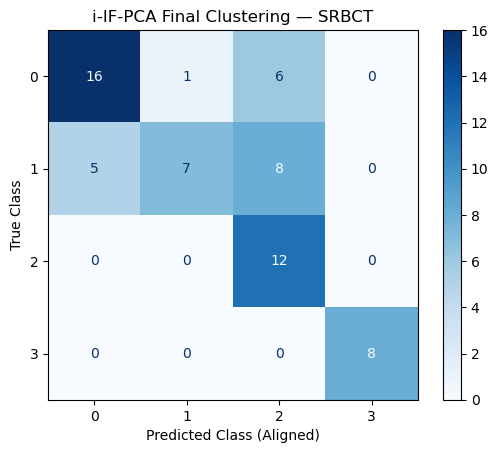

In [39]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Align final predicted cluster labels to the true classes
final_aligned = align_cluster_labels(
    y,
    iifpca_tracked["labels"]
)

# Create confusion matrix
cm = confusion_matrix(y, final_aligned)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.unique(y)
)

disp.plot(cmap="Blues", values_format="d")
plt.title("i-IF-PCA Final Clustering — SRBCT")
plt.xlabel("Predicted Class (Aligned)")
plt.ylabel("True Class")
plt.show()


### Final Clustering Confusion Matrix: i-IF-PCA

To investigate why some samples remained incorrectly clustered, we examined the confusion matrix of the final i-IF-PCA predictions. The predicted cluster IDs were aligned with the ground-truth classes for evaluation.

| True Class | Total Samples | Correct | Incorrect | Class Accuracy |
|---|---:|---:|---:|---:|
| Class 0 | 23 | 16 | 7 | 69.6% |
| Class 1 | 20 | 7 | 13 | 35.0% |
| Class 2 | 12 | 12 | 0 | 100% |
| Class 3 | 8 | 8 | 0 | 100% |

**Observations:**

- Class 1 showed the weakest clustering performance, with only 7 of its 20 samples correctly assigned after cluster alignment.
- Of the 13 incorrectly clustered Class 1 samples, 5 were assigned to Class 0 and 8 to Class 2.
- Class 0 had 7 incorrect assignments, including 6 samples assigned to Class 2.
- All samples belonging to Classes 2 and 3 were correctly clustered.
- Overall, 43 of the 63 samples were correctly clustered, producing ACC = 0.6825.

**Conclusion:**

The clustering errors were concentrated in Classes 0 and 1, particularly Class 1. This is consistent with our earlier finding that all 14 continuously incorrect samples belonged to these two classes.

The results suggest that i-IF-PCA had difficulty distinguishing some samples from these classes under the final clustering. However, the confusion matrix alone cannot establish whether these groups overlap in the original feature space or why the algorithm grouped them together.

We will compare this behavior with i-IF-Lap to investigate whether Laplacian embedding improves the separation of these classes.

In [40]:

# Run i-IF-Lap with pseudo-label tracking enabled

start_time = time.perf_counter()

iiflap_tracked = run_i_if_learn(
    X,
    K,
    method="laplacian",
    seed=42,
    max_iter=10,
    convergence_threshold=0.1,
    random_trials=200,
    ks_repetitions=100000
)

iiflap_tracked_runtime = time.perf_counter() - start_time

print("\nTracking Results")
print("Initial labels:", iiflap_tracked["initial_labels"].shape)
print("Initial features:", len(iiflap_tracked["initial_features"]))
print("Iterations recorded:", len(iiflap_tracked["history"]))
print("Final features:", len(iiflap_tracked["features"]))
print(f"Runtime: {iiflap_tracked_runtime:.2f} seconds")


C:\Users\priyam\Desktop\Semester2\Machine_Learning\Decison_Tree\Project\Clustering\Src\iiflearn.py:149: RuntimeWarning: divide by zero encountered in divide
  np.sqrt(s)


Iteration 1: features=350, w=0.3750, change=5.8627
Iteration 2: features=119, w=1.0000, change=0.2057
Iteration 3: features=154, w=1.0000, change=0.3025
Iteration 4: features=154, w=1.0000, change=0.0000
Converged after 4 iterations.

Tracking Results
Initial labels: (63,)
Initial features: 51
Iterations recorded: 4
Final features: 154
Runtime: 562.12 seconds


In [41]:

# Evaluate initial and final clustering

lap_initial_metrics = evaluate_clustering(
    y, iiflap_tracked["initial_labels"]
)

lap_final_metrics = evaluate_clustering(
    y, iiflap_tracked["labels"]
)

print("Initial IF-PCA:", lap_initial_metrics)
print("Final i-IF-Lap:", lap_final_metrics)

# Check whether predictions match previous runs
print("\nInitial labels identical to standalone IF-PCA:",
      np.array_equal(
          initial_labels,
          iiflap_tracked["initial_labels"]
      ))

print("Final labels identical to previous i-IF-Lap:",
      np.array_equal(
          iiflap_result["labels"],
          iiflap_tracked["labels"]
      ))


Initial IF-PCA: {'Accuracy': np.float64(0.5396825396825397), 'ARI': 0.14342843839726843}
Final i-IF-Lap: {'Accuracy': np.float64(0.9841269841269841), 'ARI': 0.9460009242764772}

Initial labels identical to standalone IF-PCA: True
Final labels identical to previous i-IF-Lap: True


In [42]:

# Evaluate i-IF-Lap at initialization and each iteration

lap_iteration_results = []

# Initial IF-PCA clustering
metrics = evaluate_clustering(
    y,
    iiflap_tracked["initial_labels"]
)

lap_iteration_results.append({
    "Stage": "Initialization",
    "ACC": metrics["Accuracy"],
    "ARI": metrics["ARI"],
    "Selected Features": len(iiflap_tracked["initial_features"])
})

# Iterative refinement
for step in iiflap_tracked["history"]:
    metrics = evaluate_clustering(y, step["labels"])

    lap_iteration_results.append({
        "Stage": f"Iteration {step['iteration']}",
        "ACC": metrics["Accuracy"],
        "ARI": metrics["ARI"],
        "Selected Features": step["n_features"]
    })

lap_iteration_df = pd.DataFrame(lap_iteration_results)

display(lap_iteration_df.round(4))


,Stage,ACC,ARI,Selected Features
0,Initialization,0.5397,0.1434,51
1,Iteration 1,0.9683,0.8946,350
2,Iteration 2,0.9841,0.9460,119
3,Iteration 3,0.9841,0.9460,154
4,Iteration 4,0.9841,0.9460,154


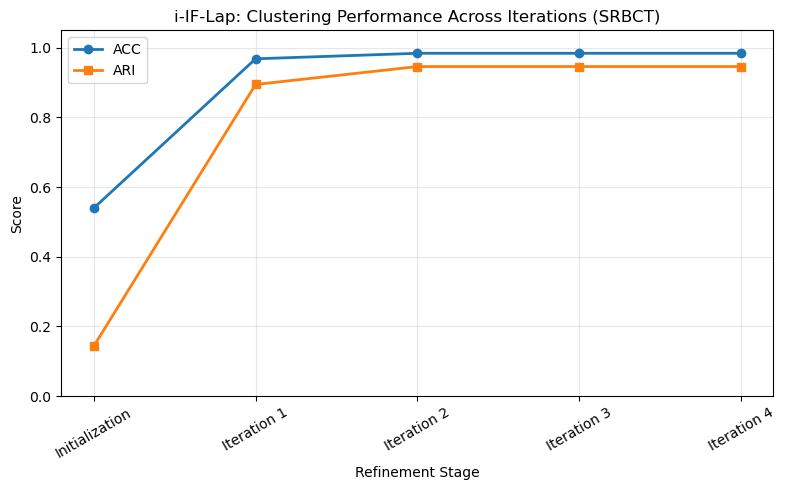

In [43]:

plt.figure(figsize=(8, 5))

plt.plot(
    lap_iteration_df["Stage"],
    lap_iteration_df["ACC"],
    marker="o",
    linewidth=2,
    label="ACC"
)

plt.plot(
    lap_iteration_df["Stage"],
    lap_iteration_df["ARI"],
    marker="s",
    linewidth=2,
    label="ARI"
)

plt.xlabel("Refinement Stage")
plt.ylabel("Score")
plt.title("i-IF-Lap: Clustering Performance Across Iterations (SRBCT)")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.tight_layout()

plt.show()


### Iteration-Wise Clustering Performance: i-IF-Lap

We evaluated ACC and ARI after each i-IF-Lap iteration to understand how iterative refinement affected clustering performance.

| Stage | ACC | ARI | Selected Features |
|---|---:|---:|---:|
| Initialization | 0.5397 | 0.1434 | 51 |
| Iteration 1 | 0.9683 | 0.8946 | 350 |
| Iteration 2 | 0.9841 | 0.9460 | 119 |
| Iteration 3 | 0.9841 | 0.9460 | 154 |
| Iteration 4 | 0.9841 | 0.9460 | 154 |

**Observations:**

- The largest improvement occurred during the first iteration, when ACC increased from 0.5397 to 0.9683 and ARI increased from 0.1434 to 0.8946.
- By iteration 2, the algorithm achieved ACC = 0.9841 and ARI = 0.9460, corresponding to 62 correctly clustered samples out of 63.
- Although the selected feature count changed from 119 to 154 between iterations 2 and 3, clustering performance remained unchanged.
- The algorithm converged after iteration 4, when the reported feature-change ratio reached zero.

**Conclusion:**

i-IF-Lap substantially improved clustering performance, with most of the improvement occurring during the first iteration. Compared with i-IF-PCA, which achieved a final ACC of 0.6825, i-IF-Lap reached 0.9841 despite starting from identical initial pseudo-labels.

This suggests that Laplacian embedding may be more effective for clustering SRBCT under the tested settings. However, further analysis is required to understand why the methods behave differently and whether this advantage is stable across datasets and random initializations.

In [44]:

# Collect initialization and iteration labels for i-IF-Lap

lap_stages = [
    ("Initialization", iiflap_tracked["initial_labels"])
]

for step in iiflap_tracked["history"]:
    lap_stages.append((
        f"Iteration {step['iteration']}",
        step["labels"]
    ))

# Align predicted clusters and check correctness
lap_correctness = {}

for name, labels in lap_stages:
    aligned = align_cluster_labels(y, labels)
    lap_correctness[name] = (aligned == y)

print("Stages recorded:", list(lap_correctness.keys()))

for name, correct in lap_correctness.items():
    print(f"{name}: {np.sum(correct)}/{len(y)} correct")


Stages recorded: ['Initialization', 'Iteration 1', 'Iteration 2', 'Iteration 3', 'Iteration 4']
Initialization: 34/63 correct
Iteration 1: 61/63 correct
Iteration 2: 62/63 correct
Iteration 3: 62/63 correct
Iteration 4: 62/63 correct


In [45]:

# Compare consecutive iterations for i-IF-Lap

lap_error_results = []

for i in range(1, len(lap_stages)):

    previous_name = lap_stages[i - 1][0]
    current_name = lap_stages[i][0]

    previous_correct = lap_correctness[previous_name]
    current_correct = lap_correctness[current_name]

    corrected = np.sum(~previous_correct & current_correct)
    new_errors = np.sum(previous_correct & ~current_correct)
    persistent_errors = np.sum(~previous_correct & ~current_correct)
    still_correct = np.sum(previous_correct & current_correct)

    lap_error_results.append({
        "Transition": f"{previous_name} → {current_name}",
        "Corrected": corrected,
        "New Errors": new_errors,
        "Persistent Errors": persistent_errors,
        "Still Correct": still_correct
    })

lap_error_df = pd.DataFrame(lap_error_results)

display(lap_error_df)


,Transition,Corrected,New Errors,Persistent Errors,Still Correct
0,Initialization → Iteration 1,29,2,0,32
1,Iteration 1 → Iteration 2,1,0,1,61
2,Iteration 2 → Iteration 3,0,0,1,62
3,Iteration 3 → Iteration 4,0,0,1,62


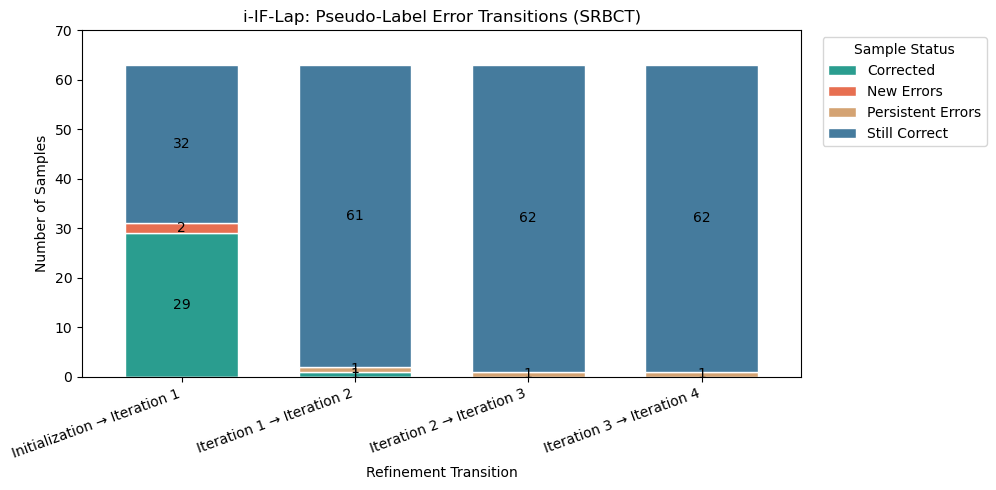

In [46]:

# Visualize pseudo-label correction and errors across iterations

plot_df = lap_error_df.set_index("Transition")[
    ["Corrected", "New Errors", "Persistent Errors", "Still Correct"]
]

colors = ["#2A9D8F", "#E76F51", "#D4A373", "#457B9D"]

ax = plot_df.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5),
    color=colors,
    edgecolor="white",
    width=0.65
)

# Display non-zero counts within each bar segment
for container in ax.containers:
    labels = [
        f"{int(bar.get_height())}" if bar.get_height() > 0 else ""
        for bar in container
    ]
    ax.bar_label(
        container,
        labels=labels,
        label_type="center",
        fontsize=10
    )

plt.title("i-IF-Lap: Pseudo-Label Error Transitions (SRBCT)")
plt.xlabel("Refinement Transition")
plt.ylabel("Number of Samples")
plt.ylim(0, 70)
plt.xticks(rotation=20, ha="right")
plt.legend(title="Sample Status", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


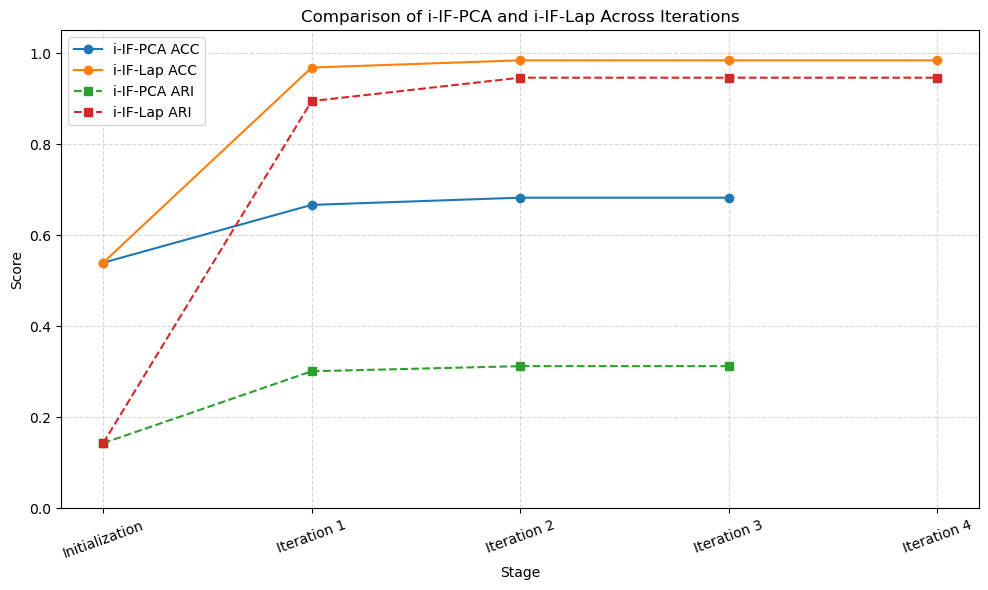

In [47]:
import pandas as pd
import matplotlib.pyplot as plt

# Stage-wise results from your notebook
pca_df = pd.DataFrame({
    "Stage": ["Initialization", "Iteration 1", "Iteration 2", "Iteration 3"],
    "ACC": [0.5397, 0.6667, 0.6825, 0.6825],
    "ARI": [0.1434, 0.3013, 0.3126, 0.3126]
})

lap_df = pd.DataFrame({
    "Stage": ["Initialization", "Iteration 1", "Iteration 2", "Iteration 3", "Iteration 4"],
    "ACC": [0.5397, 0.9683, 0.9841, 0.9841, 0.9841],
    "ARI": [0.1434, 0.8946, 0.9460, 0.9460, 0.9460]
})

# Common stage order
stage_order = ["Initialization", "Iteration 1", "Iteration 2", "Iteration 3", "Iteration 4"]

# Reindex so both methods align on same x-axis
pca_df = pca_df.set_index("Stage").reindex(stage_order)
lap_df = lap_df.set_index("Stage").reindex(stage_order)

plt.figure(figsize=(10, 6))

# Plot ACC
plt.plot(stage_order, pca_df["ACC"], marker="o", label="i-IF-PCA ACC")
plt.plot(stage_order, lap_df["ACC"], marker="o", label="i-IF-Lap ACC")

# Plot ARI
plt.plot(stage_order, pca_df["ARI"], marker="s", linestyle="--", label="i-IF-PCA ARI")
plt.plot(stage_order, lap_df["ARI"], marker="s", linestyle="--", label="i-IF-Lap ARI")

plt.title("Comparison of i-IF-PCA and i-IF-Lap Across Iterations")
plt.xlabel("Stage")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

### Comparison of i-IF-PCA and i-IF-Lap Across Iterations

This graph compares the stage-wise ACC and ARI values of i-IF-PCA and i-IF-Lap on the SRBCT dataset.  
The purpose is to see how much each iterative method improves from the same IF-PCA initialization and how quickly the performance stabilizes.

From this comparison, we can check:
- whether both methods benefit from iterative refinement,
- which method improves more strongly,
- and after which iteration the performance stops changing meaningfully.

### Sample-Level Pseudo-Label Error Analysis: i-IF-Lap

To understand how i-IF-Lap updates its pseudo-labels, we compared sample-level correctness between consecutive iterations. Predicted cluster labels were aligned with the ground-truth classes using the Hungarian algorithm for evaluation.

| Transition | Corrected | New Errors | Persistent Errors | Still Correct |
|---|---:|---:|---:|---:|
| Initialization → Iteration 1 | 29 | 2 | 0 | 32 |
| Iteration 1 → Iteration 2 | 1 | 0 | 1 | 61 |
| Iteration 2 → Iteration 3 | 0 | 0 | 1 | 62 |
| Iteration 3 → Iteration 4 | 0 | 0 | 1 | 62 |

**Observations:**

- During the first iteration, all 29 initially incorrect samples became correctly clustered, while 2 previously correct samples became incorrect.
- The first iteration increased the number of correctly clustered samples from 34 to 61, raising ACC from 0.5397 to 0.9683.
- The second iteration corrected one of the two remaining errors, increasing ACC to 0.9841.
- No additional changes in correctness occurred during iterations 3 and 4, although feature selection continued to update.

**Comparison with i-IF-PCA:**

Both methods started from identical IF-PCA pseudo-labels. However, i-IF-PCA corrected only 14 initial errors and introduced 6 new errors during the first iteration, whereas i-IF-Lap corrected all 29 initial errors and introduced only 2 new errors.

**Conclusion:**

i-IF-Lap showed substantially more effective pseudo-label refinement than i-IF-PCA on SRBCT. Most of the improvement occurred during the first iteration, and only one incorrectly clustered sample remained in the final result.

These findings suggest that Laplacian embedding may better capture the clustering structure of this dataset. However, further experiments are needed to determine whether this advantage persists across other datasets and random initializations.

In [48]:

# Find samples incorrectly clustered in the final iteration
final_incorrect_indices = np.where(
    ~lap_correctness["Iteration 4"]
)[0]

# Check whether those samples were correct at initialization
for idx in final_incorrect_indices:
    print("Sample index:", idx)
    print("True class:", y[idx])
    print("Correct at initialization:",
          lap_correctness["Initialization"][idx])

    print("Correctness across stages:")
    for stage, correct in lap_correctness.items():
        print(f"  {stage}: {'Correct' if correct[idx] else 'Incorrect'}")


Sample index: 9
True class: 0
Correct at initialization: True
Correctness across stages:
  Initialization: Correct
  Iteration 1: Incorrect
  Iteration 2: Incorrect
  Iteration 3: Incorrect
  Iteration 4: Incorrect


### Investigation of the Final Incorrectly Clustered Sample

After the final i-IF-Lap iteration, only one of the 63 SRBCT samples remained incorrectly clustered.

We identified this as **sample index 9**, belonging to true Class 0.

The sample was correctly clustered during IF-PCA initialization but became incorrect after the first i-IF-Lap iteration. It remained incorrectly clustered throughout iterations 2, 3, and 4.

**Key findings:**

- All 29 initial IF-PCA errors were corrected during the first i-IF-Lap iteration.
- Two previously correct samples became incorrect during that iteration.
- One of these new errors was corrected during iteration 2.
- Sample 9 remained incorrect through convergence.

**Conclusion:**

Although i-IF-Lap achieved very high clustering accuracy (0.9841), the iterative process introduced an incorrect assignment that persisted until convergence.

This demonstrates that iterative refinement can improve overall clustering while introducing errors that are not corrected in subsequent iterations.

However, **we can only conclude that the error persisted, not that the algorithm actively reinforced it**. Establishing reinforcement would require further analysis of how incorrect pseudo-labels influence feature selection and subsequent clustering decisions.

In [49]:

# Examine sample 9's predicted cluster across iterations

sample_idx = 9

sample_history = []

for stage_name, labels in lap_stages:
    aligned = align_cluster_labels(y, labels)

    sample_history.append({
        "Stage": stage_name,
        "True Class": y[sample_idx],
        "Predicted Class": aligned[sample_idx],
        "Correct": aligned[sample_idx] == y[sample_idx]
    })

sample_history_df = pd.DataFrame(sample_history)

display(sample_history_df)


,Stage,True Class,Predicted Class,Correct
0,Initialization,0,0,True
1,Iteration 1,0,1,False
2,Iteration 2,0,1,False
3,Iteration 3,0,1,False
4,Iteration 4,0,1,False


In [50]:

# Examine reliability weights and feature changes in i-IF-Lap

lap_reliability_df = pd.DataFrame([
    {
        "Iteration": step["iteration"],
        "Reliability Weight": step["weight"],
        "Selected Features": step["n_features"],
        "Feature Change": step["change_ratio"],
        "Sample 9 Correct": lap_correctness[
            f"Iteration {step['iteration']}"
        ][9]
    }
    for step in iiflap_tracked["history"]
])

display(lap_reliability_df.round(4))


,Iteration,Reliability Weight,Selected Features,Feature Change,Sample 9 Correct
0,1,0.375,350,5.8627,False
1,2,1.000,119,0.2057,False
2,3,1.000,154,0.3025,False
3,4,1.000,154,0.0000,False


### Reliability Weight and Persistent Pseudo-Label Error: i-IF-Lap

We examined the reliability weights and selected feature counts to investigate why sample 9 remained incorrectly clustered after the first iteration.

| Iteration | Reliability Weight | Selected Features | Sample 9 Status |
|---|---:|---:|---|
| 1 | 0.375 | 350 | Incorrect |
| 2 | 1.000 | 119 | Incorrect |
| 3 | 1.000 | 154 | Incorrect |
| 4 | 1.000 | 154 | Incorrect |

Sample 9 was correctly clustered during IF-PCA initialization but became incorrectly clustered after iteration 1.

During iteration 1, the reliability weight was 0.375, so feature selection combined KS-based information with pseudo-label-based F-statistics.

From iteration 2 onward, the reliability weight reached 1.0. Under the implemented scoring formula, this means the feature-selection scores depended entirely on F-statistics derived from the current pseudo-labels.

Because sample 9 was already incorrectly clustered, its assignment contributed to these subsequent feature calculations. However, the sample remained incorrectly clustered through convergence.

**Conclusion:** The results show that an incorrect pseudo-label persisted while the algorithm placed full weight on pseudo-label-based feature information. This is consistent with possible error reinforcement, but does not establish that the weighting mechanism caused the error to persist.

A controlled experiment that changes the contribution of pseudo-label-based information would help investigate this possibility.

In [51]:

from pathlib import Path
import shutil

original = Path("Src/iiflearn.py")
ablation = Path("Src/iiflearn_ablation.py")

if not ablation.exists():
    shutil.copy2(original, ablation)
    print("Experimental copy created:", ablation)
else:
    print("Experimental file already exists. No changes made.")


Experimental copy created: Src\iiflearn_ablation.py


In [52]:

from Src.iiflearn_ablation import run_i_if_learn as run_i_if_learn_ablation

print("Ablation implementation imported successfully!")


Ablation implementation imported successfully!


### Reliability Weight Ablation: Investigating Pseudo-Label Error Persistence

Our original i-IF-Lap experiment achieved an ACC of 0.9841 and ARI of 0.9460. However, sample 9, which was correctly clustered during initialization, became incorrectly clustered after iteration 1 and remained incorrect through convergence.

We observed that the reliability weight reached 1.0 in later iterations, causing feature selection to rely entirely on pseudo-label-based scores.

To investigate whether this contributed to the persistent error, we created a separate experimental implementation that **caps the reliability weight at 0.5**.

This experiment preserves the original dataset, initialization procedure, embedding method, and clustering settings. Only the maximum contribution of pseudo-label-based information is modified.

We will compare the original and experimental methods using ACC, ARI, selected feature counts, iteration behavior, and sample 9's clustering outcome.

This is an additional sensitivity experiment, not part of the original paper's replication.

In [54]:

# Run i-IF-Lap with reliability weight capped at 0.5

start_time = time.perf_counter()

iiflap_ablation = run_i_if_learn_ablation(
    X,
    K,
    method="laplacian",
    seed=42,
    max_iter=10,
    convergence_threshold=0.1,
    random_trials=200,
    ks_repetitions=100000
)

ablation_runtime = time.perf_counter() - start_time

# Evaluate final clustering
ablation_metrics = evaluate_clustering(
    y,
    iiflap_ablation["labels"]
)

print("\nAblation Experiment Results")
print(f"ACC: {ablation_metrics['Accuracy']:.4f}")
print(f"ARI: {ablation_metrics['ARI']:.4f}")
print("Iterations:", len(iiflap_ablation["history"]))
print("Selected features:", len(iiflap_ablation["features"]))
print(f"Runtime: {ablation_runtime:.2f} seconds")

# Check sample 9
ablation_aligned = align_cluster_labels(
    y,
    iiflap_ablation["labels"]
)

print("\nSample 9:")
print("True class:", y[9])
print("Predicted class:", ablation_aligned[9])
print("Correct:", ablation_aligned[9] == y[9])


C:\Users\priyam\Desktop\Semester2\Machine_Learning\Decison_Tree\Project\Clustering\Src\iiflearn_ablation.py:149: RuntimeWarning: divide by zero encountered in divide
  np.sqrt(s)


Iteration 1: features=350, w=0.3750, change=5.8627
Iteration 2: features=445, w=0.5000, change=0.6229
Iteration 3: features=445, w=0.5000, change=0.0000
Converged after 3 iterations.

Ablation Experiment Results
ACC: 0.9683
ARI: 0.8946
Iterations: 3
Selected features: 445
Runtime: 227.54 seconds

Sample 9:
True class: 0
Predicted class: 1
Correct: False


### Reliability Weight Ablation: Results and Interpretation

To investigate whether excessive reliance on pseudo-label-based feature information contributed to persistent clustering errors, we conducted an ablation experiment that capped the reliability weight at 0.5.

All other algorithm settings were preserved, and the original implementation was kept unchanged for replication.

| Metric | Original i-IF-Lap | Weight-Capped Ablation |
|---|---:|---:|
| ACC | 0.9841 | 0.9683 |
| ARI | 0.9460 | 0.8946 |
| Iterations | 4 | 3 |
| Final Selected Features | 154 | 445 |
| Sample 9 Correct | No | No |

**Observations:**

- During iteration 1, both implementations used a reliability weight of 0.375 and selected 350 features.
- From iteration 2 onward, the original algorithm used a reliability weight of 1.0, while the experimental version limited it to 0.5.
- The ablation selected 445 features by iteration 2 and converged after iteration 3.
- The weight-capped version achieved slightly lower clustering performance than the original method.
- Sample 9 remained incorrectly clustered even after limiting pseudo-label influence.

**Conclusion:**

The ablation demonstrates that changing the reliability weight can substantially affect feature selection and clustering performance. However, limiting the weight to 0.5 did not correct sample 9's persistent clustering error.

Therefore, this experiment does not establish that full reliance on pseudo-label information caused the error to persist. It also suggests that retaining some KS-based information does not necessarily improve clustering performance.

These findings are limited to one dataset and one initialization. Further controlled experiments would be required to make broader claims about the reliability-weighting mechanism.

In [56]:

# Compare final incorrect samples in both implementations

original_aligned = align_cluster_labels(
    y, iiflap_tracked["labels"]
)

ablation_aligned = align_cluster_labels(
    y, iiflap_ablation["labels"]
)

original_errors = set(np.where(original_aligned != y)[0])
ablation_errors = set(np.where(ablation_aligned != y)[0])

print("Original incorrect samples:", sorted(original_errors))
print("Ablation incorrect samples:", sorted(ablation_errors))

print("Errors shared by both:", sorted(original_errors & ablation_errors))
print("Errors only in ablation:", sorted(ablation_errors - original_errors))
print("Errors only in original:", sorted(original_errors - ablation_errors))


Original incorrect samples: [np.int64(9)]
Ablation incorrect samples: [np.int64(3), np.int64(9)]
Errors shared by both: [np.int64(9)]
Errors only in ablation: [np.int64(3)]
Errors only in original: []


### Sample-Level Comparison: Original i-IF-Lap vs. Weight-Capped Ablation

To investigate the effect of limiting pseudo-label influence, we compared the final incorrect samples from the original i-IF-Lap implementation and the experimental version with the reliability weight capped at 0.5.

| Sample Index | Original i-IF-Lap | Weight-Capped Ablation |
|---|---|---|
| 9 | Incorrect | Incorrect |
| 3 | Correct | Incorrect |

**Observations:**

- Sample 9 remained incorrectly clustered in both implementations, indicating that reducing the reliability weight to 0.5 did not resolve its error.
- Sample 3 was correctly clustered in the original implementation but became incorrectly clustered in the ablation.
- The original method achieved ACC = 0.9841 (62/63 correct), while the weight-capped version achieved ACC = 0.9683 (61/63 correct).
- The ablation also changed the number of final selected features from 154 to 445.

**Conclusion:**

The experiment demonstrates that limiting the reliability weight changes feature selection and can affect individual clustering assignments. However, the intervention did not correct sample 9 and introduced an additional error involving sample 3.

These results do not provide evidence that capping the reliability weight at 0.5 prevents persistent pseudo-label errors. They also do not establish that pseudo-label feedback caused the original error.

Therefore, we cannot conclude that error reinforcement was responsible for sample 9's incorrect assignment based on this experiment alone.

In [58]:

import inspect

from Src.iiflearn import run_i_if_learn
from Src.ifpca import run_ifpca

print("IF-PCA parameters:")
print(inspect.signature(run_ifpca))

print("\ni-IF-Learn parameters:")
print(inspect.signature(run_i_if_learn))

print("\nIF-PCA initialization inside i-IF-Learn:")
source = inspect.getsource(run_i_if_learn)

start = source.index(") = run_ifpca(")
print(source[start:start + 180])


IF-PCA parameters:
(X, K, threshold=None, null_rep=100000, random_state=42)

i-IF-Learn parameters:
(X, K, method='PCA', seed=42, max_iter=10, convergence_threshold=0.1, random_trials=200, ks_repetitions=100000)

IF-PCA initialization inside i-IF-Learn:
) = run_ifpca(
        X,
        K,
        null_rep=ks_repetitions,
        random_state=seed
    )

    # NEW: Preserve initial IF-PCA predictions and features.
    # These are 


In [59]:

# Compare standalone IF-PCA with i-IF-PCA initialization

labels_match = np.array_equal(
    initial_labels,
    iifpca_tracked["initial_labels"]
)

features_match = np.array_equal(
    np.sort(selected_features),
    np.sort(iifpca_tracked["initial_features"])
)

print("Initial labels identical:", labels_match)
print("Initial selected features identical:", features_match)
print("Number of selected features:",
      len(iifpca_tracked["initial_features"]))


Initial labels identical: True
Initial selected features identical: True
Number of selected features: 51


In [60]:

from Src.iiflearn import (
    compute_reliability_weight,
    final_reliability_weight
)

import inspect

print("Reliability score calculation:")
print(inspect.getsource(compute_reliability_weight))

print("\nFinal reliability weight calculation:")
print(inspect.getsource(final_reliability_weight))


Reliability score calculation:
def compute_reliability_weight(
    reliability_pvalues,
    n,
    c_constant=0.6
):
    """
    Compute Higher-Criticism-style reliability
    scores for currently selected features.
    """

    sorted_p = np.sort(reliability_pvalues)

    s = len(sorted_p)

    j_values = np.arange(1, s + 1)

    scores = (
        np.sqrt(s)
        * (j_values / n - sorted_p)
        / np.sqrt(sorted_p * (1 - sorted_p))
    )

    return (
        sorted_p,
        scores
    )


Final reliability weight calculation:
def final_reliability_weight(
    reliability_scores,
    c_constant=0.6
):
    """
    Convert the reliability statistic into the
    final information weight used by i-IF-Learn.
    """

    two_thirds = int(
        len(reliability_scores) * 2 / 3
    )

    stable_scores = reliability_scores[-two_thirds:]

    s = len(stable_scores)

    b = np.sqrt(
        2 * np.log(np.log(s))
    )

    c = (
        2 * np.log(np.log(s))
        + 0.5 * np.log(

In [61]:

from Src.iiflearn import generate_random_f_reference
import inspect

print(inspect.getsource(generate_random_f_reference))


def generate_random_f_reference(
    X,
    K,
    num_selected_features,
    component,
    method="PCA",
    num_trials=200,
    random_seed=42
):
    """
    Generate the random F-statistic reference
    distribution used to estimate reliability.

    For each trial:
    1. Randomly select features.
    2. Embed those features.
    3. Run KMeans.
    4. Compute ANOVA F-statistics.
    """

    np.random.seed(random_seed)
    random.seed(random_seed)

    n, p = X.shape

    scaler = StandardScaler()

    Z = scaler.fit_transform(X)

    Z = (
        Z * np.sqrt((n - 1) / n)
    )

    random_f_values = []

    for trial in range(num_trials):

        random_indices = random.sample(
            range(p),
            num_selected_features
        )

        X_random = Z[:, random_indices]

        embedding = create_embedding(
            X_random,
            n_components=component,
            method=method
        )

        kmeans = KMeans(
            n_clusters=K,
            n

In [62]:

# Test reproducibility with a small number of random trials

reference_1 = generate_random_f_reference(
    X=X,
    K=K,
    num_selected_features=51,
    component=K + 2,
    method="PCA",
    num_trials=5,
    random_seed=42
)

reference_2 = generate_random_f_reference(
    X=X,
    K=K,
    num_selected_features=51,
    component=K + 2,
    method="PCA",
    num_trials=5,
    random_seed=42
)

print("Reference shape:", reference_1.shape)
print("Identical results:", np.array_equal(reference_1, reference_2))


Reference shape: (255,)
Identical results: True


In [63]:

# Show random seed settings used by our implementation

import inspect

source = inspect.getsource(run_i_if_learn)

for line_number, line in enumerate(source.splitlines(), start=1):
    if "seed" in line or "random" in line:
        print(f"{line_number}: {line}")


5:     seed=42,
8:     random_trials=200,
44:     np.random.seed(seed)
45:     random.seed(seed)
61:         random_state=seed
82:     # Create random F reference
85:     random_f_reference = generate_random_f_reference(
91:         num_trials=random_trials,
92:         random_seed=seed
145:                 f_score < random_f_reference
240:             random_state=42


## 5. Initialization and Stability Analysis

To investigate the reproducibility and stability of the clustering methods, we will repeat experiments using different random seeds.

We will evaluate three methods: IF-PCA, i-IF-PCA, and i-IF-Lap.

For each method, we will examine:

- **Performance stability:** Mean, standard deviation, and range of ACC and ARI across runs.
- **Feature-selection stability:** Consistency of selected feature subsets, measured using Jaccard similarity.
- **Runtime and feature counts:** Differences in execution time and the number of features selected.

We will first vary the exposed random seed while preserving the authors' original K-Means settings (`random_state=42`). This tests sensitivity to the other randomized operations in the implementation, not K-Means initialization itself.

A separate experiment may investigate the effect of varying K-Means initialization.

We will begin with five random seeds on SRBCT before extending the analysis to the iterative methods and remaining datasets.

In [72]:

#Random Seed: A seed is a number used to initialize a random number generator so that the results can be reproduced. In our IF-PCA experiment, seeds 0–4 control the random values generated during the KS null distribution simulation, which influences feature selection and clustering performance. K-Means uses a fixed seed of 42 throughout these experiments.
# Seeds for repeated experiments
stability_seeds = list(range(10))

print("Number of runs:", len(stability_seeds))
print("Seeds:", stability_seeds)


Number of runs: 10
Seeds: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [73]:

# Run IF-PCA with 5 different random seeds

ifpca_stability_results = []
ifpca_feature_sets = {}

for seed in stability_seeds:
    start_time = time.perf_counter()

    labels, features, embedding, ks_scores, p_values = run_ifpca(
        X,
        K,
        threshold=None,
        null_rep=100000,
        random_state=seed
    )

    runtime = time.perf_counter() - start_time

    # Evaluate clustering performance
    metrics = evaluate_clustering(y, labels)

    # Store evaluation results
    ifpca_stability_results.append({
        "Seed": seed,
        "ACC": metrics["Accuracy"],
        "ARI": metrics["ARI"],
        "Selected Features": len(features),
        "Runtime (s)": runtime
    })

    # Store feature indices for Jaccard similarity later
    ifpca_feature_sets[seed] = set(features.tolist())

    print(f"Seed {seed} completed")

# Convert results into a DataFrame
ifpca_stability_df = pd.DataFrame(ifpca_stability_results)

display(ifpca_stability_df.round(4))


Seed 0 completed
Seed 1 completed
Seed 2 completed
Seed 3 completed
Seed 4 completed
Seed 5 completed
Seed 6 completed
Seed 7 completed
Seed 8 completed
Seed 9 completed


,Seed,ACC,ARI,Selected Features,Runtime (s)
0,0,0.7143,0.3557,133,26.0803
1,1,0.5397,0.1434,51,28.2015
2,2,0.5397,0.1434,51,26.5548
3,3,0.5397,0.1434,51,27.6657
4,4,0.5397,0.1434,51,26.1423
5,5,0.5397,0.1434,51,28.6249
6,6,0.5397,0.1434,51,26.6423
7,7,0.5397,0.1434,51,23.5133
8,8,0.7143,0.3557,133,26.0037
9,9,0.5397,0.1434,51,26.6503


In [74]:

# Summary statistics for IF-PCA stability

summary_columns = [
    "ACC",
    "ARI",
    "Selected Features",
    "Runtime (s)"
]

ifpca_stability_summary = (
    ifpca_stability_df[summary_columns]
    .agg(["mean", "std", "min", "max"])
)

display(ifpca_stability_summary.round(4))


,ACC,ARI,Selected Features,Runtime (s)
mean,0.5746,0.1859,67.4000,26.6079
std,0.0736,0.0895,34.5742,1.4209
min,0.5397,0.1434,51.0000,23.5133
max,0.7143,0.3557,133.0000,28.6249


In [75]:

from itertools import combinations

jaccard_results = []

for seed1, seed2 in combinations(stability_seeds, 2):
    features1 = ifpca_feature_sets[seed1]
    features2 = ifpca_feature_sets[seed2]

    intersection = len(features1 & features2)
    union = len(features1 | features2)

    jaccard = intersection / union

    jaccard_results.append({
        "Seed 1": seed1,
        "Seed 2": seed2,
        "Jaccard": jaccard
    })

ifpca_jaccard_df = pd.DataFrame(jaccard_results)

display(ifpca_jaccard_df.round(4))

print(
    "Mean Jaccard similarity:",
    round(ifpca_jaccard_df["Jaccard"].mean(), 4)
)


,Seed 1,Seed 2,Jaccard
0,0,1,0.3835
1,0,2,0.3835
2,0,3,0.3835
3,0,4,0.3835
4,0,5,0.3835
5,0,6,0.3835
6,0,7,0.3835
7,0,8,1.0000
8,0,9,0.3835
9,1,2,1.0000


Mean Jaccard similarity: 0.7808


### IF-PCA Stability Analysis (10 Seeds)

We evaluated IF-PCA on SRBCT using ten random seeds to investigate the sensitivity of feature selection and clustering performance to the KS null simulation.

The results showed two distinct outcomes. Seeds 0 and 8 selected 133 genes and achieved an ACC of 0.7143 and ARI of 0.3557. The remaining eight seeds selected 51 genes and achieved an ACC of 0.5397 and ARI of 0.1434.

Feature-selection stability was evaluated using pairwise Jaccard similarity. The overall mean similarity was 0.7808 across 45 comparisons. Feature sets were identical within each group (Jaccard = 1.0), while the similarity between groups was 0.3835.

These findings suggest that IF-PCA's HCT feature-selection threshold is sensitive to the random seed used for KS null simulation. However, the variation was structured into two distinct feature-selection outcomes rather than completely different selections across runs.

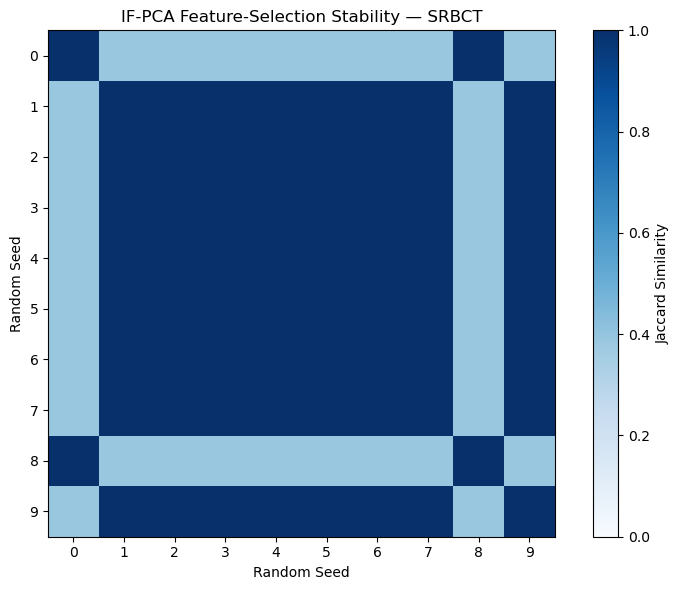

In [76]:

# Create a 10 x 10 Jaccard similarity matrix

jaccard_matrix = pd.DataFrame(
    1.0,
    index=stability_seeds,
    columns=stability_seeds
)

for _, row in ifpca_jaccard_df.iterrows():
    s1 = int(row["Seed 1"])
    s2 = int(row["Seed 2"])

    jaccard_matrix.loc[s1, s2] = row["Jaccard"]
    jaccard_matrix.loc[s2, s1] = row["Jaccard"]

plt.figure(figsize=(8, 6))

plt.imshow(jaccard_matrix, cmap="Blues", vmin=0, vmax=1)

plt.colorbar(label="Jaccard Similarity")
plt.xticks(range(10), stability_seeds)
plt.yticks(range(10), stability_seeds)

plt.xlabel("Random Seed")
plt.ylabel("Random Seed")
plt.title("IF-PCA Feature-Selection Stability — SRBCT")

plt.tight_layout()
plt.show()


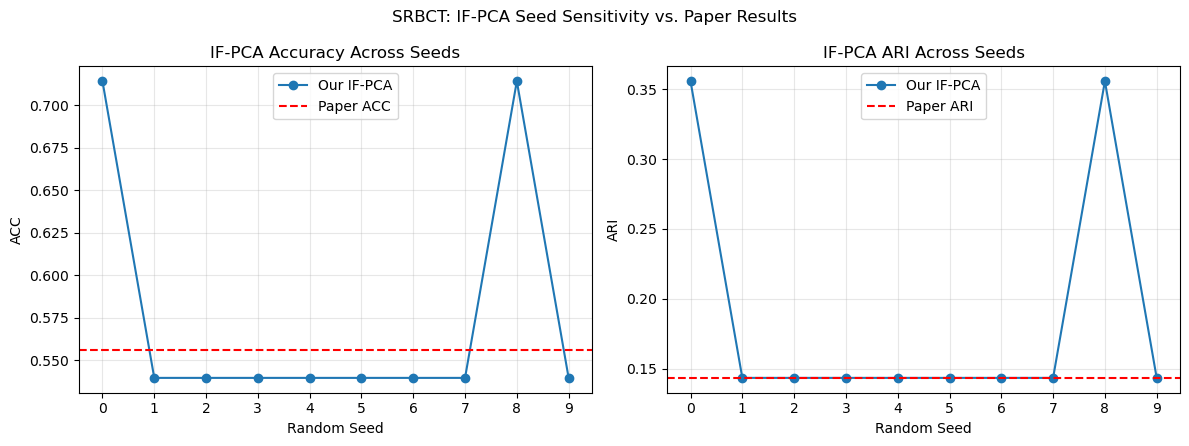

In [77]:

# IF-PCA stability: ACC and ARI vs. random seed

paper_acc = 0.556
paper_ari = 0.143

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Accuracy
axes[0].plot(
    ifpca_stability_df["Seed"],
    ifpca_stability_df["ACC"],
    marker="o",
    label="Our IF-PCA"
)
axes[0].axhline(
    y=paper_acc,
    color="red",
    linestyle="--",
    label="Paper ACC"
)
axes[0].set_title("IF-PCA Accuracy Across Seeds")
axes[0].set_xlabel("Random Seed")
axes[0].set_ylabel("ACC")
axes[0].set_xticks(stability_seeds)
axes[0].legend()
axes[0].grid(alpha=0.3)

# Adjusted Rand Index
axes[1].plot(
    ifpca_stability_df["Seed"],
    ifpca_stability_df["ARI"],
    marker="o",
    label="Our IF-PCA"
)
axes[1].axhline(
    y=paper_ari,
    color="red",
    linestyle="--",
    label="Paper ARI"
)
axes[1].set_title("IF-PCA ARI Across Seeds")
axes[1].set_xlabel("Random Seed")
axes[1].set_ylabel("ARI")
axes[1].set_xticks(stability_seeds)
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.suptitle("SRBCT: IF-PCA Seed Sensitivity vs. Paper Results")
plt.tight_layout()
plt.show()


### IF-PCA Seed Sensitivity vs. Published Results

The plots compare IF-PCA clustering performance across ten random seeds with the values reported in the paper.

Eight runs achieved an ACC of 0.5397 and ARI of 0.1434, while seeds 0 and 8 achieved higher scores of 0.7143 ACC and 0.3557 ARI. The mean ACC across ten seeds was 0.5746, compared with 0.556 reported in the paper.

The variation in performance was associated with changes in the number of selected features: the higher-performing runs selected 133 genes, while the remaining runs selected 51.

These results suggest that IF-PCA's feature selection and clustering performance are sensitive to the random seed used for KS null simulation. However, the authors' exact experimental seed settings are not documented, so the difference from the published results cannot be attributed to a specific cause.

In [79]:
# i-IF-PCA stability experiment: 10 random seeds
# i-IF-PCA Stability Analysis (10 Seeds)
# Run i-IF-PCA using seeds 0–9 to evaluate the stability of clustering
# performance, feature selection, and runtime.
# Each seed is used for both the KS null simulation (IF-PCA initialization)
# and random F-statistic reference generation, consistent with our original
# implementation. K-Means remains fixed at random_state=42.
# We will compare ACC, ARI, and feature-selection stability across runs
# and against the results reported in the paper.
import time

iifpca_stability_results = []
iifpca_feature_sets = {}

for seed in stability_seeds:
    start_time = time.perf_counter()

    result = run_i_if_learn(
        X=X,
        K=K,
        method="PCA",
        seed=seed,
        max_iter=10,
        convergence_threshold=0.1,
        random_trials=200,
        ks_repetitions=100000
    )

    runtime = time.perf_counter() - start_time

    # Evaluate final clustering predictions
    metrics = evaluate_clustering(y, result["labels"])

    # Store results
    iifpca_stability_results.append({
        "Seed": seed,
        "ACC": metrics["Accuracy"],
        "ARI": metrics["ARI"],
        "Selected Features": len(result["features"]),
        "Iterations": len(result["history"]),
        "Runtime (s)": runtime
    })

    # Store selected feature indices
    iifpca_feature_sets[seed] = set(result["features"].tolist())

    print(f"Seed {seed} completed")

iifpca_stability_df = pd.DataFrame(iifpca_stability_results)
display(iifpca_stability_df.round(4))

Iteration 1: features=88, w=1.0000, change=0.4887
Iteration 2: features=100, w=1.0000, change=0.1932
Iteration 3: features=133, w=1.0000, change=0.7300
Iteration 4: features=159, w=1.0000, change=0.5414
Iteration 5: features=166, w=1.0000, change=0.2075
Iteration 6: features=185, w=1.0000, change=0.2410
Iteration 7: features=185, w=1.0000, change=0.0000
Converged after 7 iterations.
Seed 0 completed


C:\Users\priyam\Desktop\Semester2\Machine_Learning\Decison_Tree\Project\Clustering\Src\iiflearn.py:149: RuntimeWarning: divide by zero encountered in divide
  np.sqrt(s)


Iteration 1: features=349, w=0.3750, change=5.8431
Iteration 2: features=185, w=1.0000, change=0.3410
Iteration 3: features=153, w=1.0000, change=0.0378
Converged after 3 iterations.
Seed 1 completed
Iteration 1: features=351, w=0.3750, change=5.8824
Iteration 2: features=185, w=1.0000, change=0.3362
Iteration 3: features=153, w=1.0000, change=0.0378
Converged after 3 iterations.
Seed 2 completed


C:\Users\priyam\Desktop\Semester2\Machine_Learning\Decison_Tree\Project\Clustering\Src\iiflearn.py:149: RuntimeWarning: divide by zero encountered in divide
  np.sqrt(s)


Iteration 1: features=350, w=0.3750, change=5.8627
Iteration 2: features=185, w=1.0000, change=0.3400
Iteration 3: features=153, w=1.0000, change=0.0378
Converged after 3 iterations.
Seed 3 completed


C:\Users\priyam\Desktop\Semester2\Machine_Learning\Decison_Tree\Project\Clustering\Src\iiflearn.py:149: RuntimeWarning: divide by zero encountered in divide
  np.sqrt(s)


... (6 outputs left out)

Iteration 1: features=349, w=0.3750, change=5.8431
Iteration 2: features=185, w=1.0000, change=0.3410
Iteration 3: features=153, w=1.0000, change=0.0378
Converged after 3 iterations.
Seed 7 completed
Iteration 1: features=88, w=1.0000, change=0.4887
Iteration 2: features=100, w=1.0000, change=0.1932
Iteration 3: features=133, w=1.0000, change=0.7300
Iteration 4: features=159, w=1.0000, change=0.5414
Iteration 5: features=166, w=1.0000, change=0.2075
Iteration 6: features=185, w=1.0000, change=0.2410
Iteration 7: features=185, w=1.0000, change=0.0000
Converged after 7 iterations.
Seed 8 completed


C:\Users\priyam\Desktop\Semester2\Machine_Learning\Decison_Tree\Project\Clustering\Src\iiflearn.py:149: RuntimeWarning: divide by zero encountered in divide
  np.sqrt(s)


Iteration 1: features=355, w=0.3750, change=5.9608
Iteration 2: features=185, w=1.0000, change=0.3268
Iteration 3: features=153, w=1.0000, change=0.0378
Converged after 3 iterations.
Seed 9 completed


,Seed,ACC,ARI,Selected Features,Iterations,Runtime (s)
0,0,0.8095,0.5865,185,7,609.8357
1,1,0.6825,0.3126,153,3,490.5685
2,2,0.6825,0.3126,153,3,269.2199
3,3,0.6825,0.3126,153,3,230.0493
4,4,0.6825,0.3126,153,3,230.7989
5,5,0.6825,0.3126,153,3,223.3979
6,6,0.6825,0.3126,153,3,241.6904
7,7,0.6825,0.3126,153,3,235.6163
8,8,0.8095,0.5865,185,7,243.8620
9,9,0.6825,0.3126,153,3,254.2029


In [2]:

print("Results DataFrame available:",
      "iifpca_stability_df" in globals())

print("Selected feature sets available:",
      "iifpca_feature_sets" in globals())


Results DataFrame available: False
Selected feature sets available: False


In [3]:

import pandas as pd

# Restore completed i-IF-PCA stability experiment
# Values recovered from saved notebook output

iifpca_stability_df = pd.DataFrame({
    "Seed": list(range(10)),
    "ACC": [0.8095, 0.6825, 0.6825, 0.6825, 0.6825,
            0.6825, 0.6825, 0.6825, 0.8095, 0.6825],
    "ARI": [0.5865, 0.3126, 0.3126, 0.3126, 0.3126,
            0.3126, 0.3126, 0.3126, 0.5865, 0.3126],
    "Selected Features": [185, 153, 153, 153, 153,
                          153, 153, 153, 185, 153],
    "Iterations": [7, 3, 3, 3, 3, 3, 3, 3, 7, 3],
    "Runtime (s)": [
        609.8357, 490.5685, 269.2199, 230.0493, 230.7989,
        223.3979, 241.6904, 235.6513, 243.8620, 254.2029
    ]
})

display(iifpca_stability_df)


,Seed,ACC,ARI,Selected Features,Iterations,Runtime (s)
0,0,0.8095,0.5865,185,7,609.8357
1,1,0.6825,0.3126,153,3,490.5685
2,2,0.6825,0.3126,153,3,269.2199
3,3,0.6825,0.3126,153,3,230.0493
4,4,0.6825,0.3126,153,3,230.7989
5,5,0.6825,0.3126,153,3,223.3979
6,6,0.6825,0.3126,153,3,241.6904
7,7,0.6825,0.3126,153,3,235.6513
8,8,0.8095,0.5865,185,7,243.8620
9,9,0.6825,0.3126,153,3,254.2029


In [4]:
# i-IF-PCA: 10-seed stability summary

iifpca_stability_summary = (
    iifpca_stability_df[
        ["ACC", "ARI", "Selected Features", "Iterations", "Runtime (s)"]
    ]
    .agg(["mean", "std", "min", "max"])
)

display(iifpca_stability_summary.round(4))


,ACC,ARI,Selected Features,Iterations,Runtime (s)
mean,0.7079,0.3674,159.4000,3.8000,302.9277
std,0.0535,0.1155,13.4924,1.6865,133.9633
min,0.6825,0.3126,153.0000,3.0000,223.3979
max,0.8095,0.5865,185.0000,7.0000,609.8357


### i-IF-PCA Random-Seed Stability Analysis

I evaluated i-IF-PCA on SRBCT using 10 random seeds (0–9) to examine the stability of clustering performance, feature selection, and convergence. Each seed controlled both the KS null simulation during IF-PCA initialization and the random F-statistic reference generation, while K-Means remained fixed at seed 42.

The mean ACC across the 10 runs was **0.7079 ± 0.0535**, and the mean ARI was **0.3674 ± 0.1155**. Eight seeds produced an ACC of 0.6825 and ARI of 0.3126, matching my original seed-42 experiment. These runs selected 153 features and converged in 3 iterations.

Seeds 0 and 8 achieved higher performance, with an ACC of 0.8095 and ARI of 0.5865. Both selected 185 features and required 7 iterations to converge.

Compared with the paper's reported ACC of 0.587 and ARI of 0.259, all 10 runs achieved higher scores. However, the exact experimental seeds used by the authors are not documented, so the reason for this difference remains uncertain.

Overall, the results suggest that **i-IF-PCA is sensitive to random seeds**, although most runs produced the same performance and feature counts. The higher-performing runs also required more iterations and selected more features. Further analysis of the selected feature sets is needed to determine whether matching feature counts correspond to identical genes.

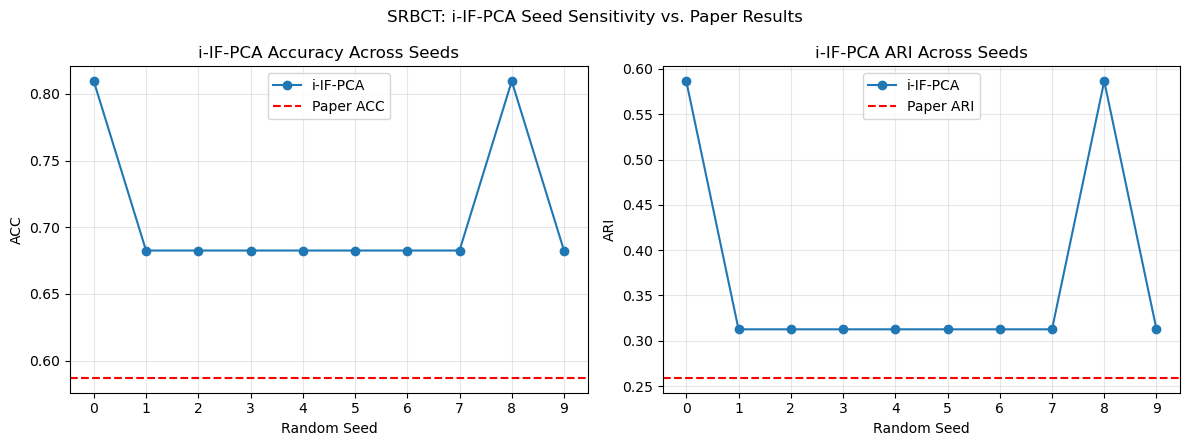

In [6]:
import matplotlib.pyplot as plt
# i-IF-PCA: ACC and ARI across 10 random seeds

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

paper_acc = 0.587
paper_ari = 0.259

axes[0].plot(
    iifpca_stability_df["Seed"],
    iifpca_stability_df["ACC"],
    marker="o",
    label="i-IF-PCA"
)
axes[0].axhline(
    paper_acc, color="red", linestyle="--",
    label="Paper ACC"
)
axes[0].set_title("i-IF-PCA Accuracy Across Seeds")
axes[0].set_xlabel("Random Seed")
axes[0].set_ylabel("ACC")
axes[0].set_xticks(range(10))
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    iifpca_stability_df["Seed"],
    iifpca_stability_df["ARI"],
    marker="o",
    label="i-IF-PCA"
)
axes[1].axhline(
    paper_ari, color="red", linestyle="--",
    label="Paper ARI"
)
axes[1].set_title("i-IF-PCA ARI Across Seeds")
axes[1].set_xlabel("Random Seed")
axes[1].set_ylabel("ARI")
axes[1].set_xticks(range(10))
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.suptitle("SRBCT: i-IF-PCA Seed Sensitivity vs. Paper Results")
plt.tight_layout()
plt.show()


In [10]:

from pathlib import Path

print("Current directory:", Path.cwd())
print("\nFiles and folders:")

for path in Path(".").iterdir():
    print(path.name)


Current directory: C:\Users\priyam\Desktop\Semester2\Machine_Learning\Decison_Tree\Project\Clustering

Files and folders:
.ipynb_checkpoints
01_SRBCT_Replication_and_Analysis.ipynb
02_SRBCT_Baseline_Comparison.ipynb.ipynb
10 Gene Microarray Datasets
10 Gene Microarray Datasets.zip
8 Single-Cell RNA-seq Datasets
8 Single-Cell RNA-seq Datasets.zip
dec_srbct_30_results.csv
experiments.ipynb
iiflap_10_runs.csv
iiflap_10_runs_summary.csv
ma26a.pdf
Project_acceptance1.png
project_acceptance2.png
Project_Flow.txt
Project_Plan.ipynb
Proposal_dRAFT.docx
scfs_10_runs.csv
scfs_10_runs_summary.csv
seurat_data
Src
Src.zip
umap_30_results.csv
Untitled.ipynb
Untitled1.ipynb
~$oposal_dRAFT.docx


In [11]:

import json
from pathlib import Path

notebook_path = Path("01_SRBCT_Replication_and_Analysis.ipynb")

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

keywords = ["iifpca_feature_sets", "selected_features", "iifpca_stability"]

for i, cell in enumerate(notebook["cells"]):
    source = "".join(cell.get("source", []))

    if any(keyword in source for keyword in keywords):
        print(f"Cell {i}:")
        print(source[:400])
        print("-" * 50)


Cell 8:

# Unpack the IF-PCA results
initial_labels, selected_features, pca_embedding, ks_scores, ks_pvalues = ifpca_result

print("Number of selected features:", len(selected_features))
print("Predicted cluster labels:", np.unique(initial_labels))
print("Number of PCA components:", pca_embedding.shape[1])

--------------------------------------------------
Cell 71:

# Compare standalone IF-PCA with i-IF-PCA initialization

labels_match = np.array_equal(
    initial_labels,
    iifpca_tracked["initial_labels"]
)

features_match = np.array_equal(
    np.sort(selected_features),
    np.sort(iifpca_tracked["initial_features"])
)

print("Initial labels identical:", labels_match)
print("Initial selected features identical:", features_match)
print("Number of select
--------------------------------------------------
Cell 74:

# Test reproducibility with a small number of random trials

reference_1 = generate_random_f_reference(
    X=X,
    K=K,
    num_selected_features=51,
    component=K +

In [12]:

# Inspect the saved output of the original 10-seed experiment

cell = notebook["cells"][85]

print("Number of saved outputs:", len(cell.get("outputs", [])))

for output in cell.get("outputs", []):
    if "text" in output:
        print("".join(output["text"])[:1500])
    elif "data" in output:
        data = output["data"]
        print("Available output formats:", list(data.keys()))
        if "text/plain" in data:
            print("".join(data["text/plain"])[:1500])


Number of saved outputs: 16
Iteration 1: features=88, w=1.0000, change=0.4887
Iteration 2: features=100, w=1.0000, change=0.1932
Iteration 3: features=133, w=1.0000, change=0.7300
Iteration 4: features=159, w=1.0000, change=0.5414
Iteration 5: features=166, w=1.0000, change=0.2075
Iteration 6: features=185, w=1.0000, change=0.2410
Iteration 7: features=185, w=1.0000, change=0.0000
Converged after 7 iterations.
Seed 0 completed

C:\Users\priyam\Desktop\Semester2\Machine_Learning\Decison_Tree\Project\Clustering\Src\iiflearn.py:149: RuntimeWarning: divide by zero encountered in divide
  np.sqrt(s)

Iteration 1: features=349, w=0.3750, change=5.8431
Iteration 2: features=185, w=1.0000, change=0.3410
Iteration 3: features=153, w=1.0000, change=0.0378
Converged after 3 iterations.
Seed 1 completed
Iteration 1: features=351, w=0.3750, change=5.8824
Iteration 2: features=185, w=1.0000, change=0.3362
Iteration 3: features=153, w=1.0000, change=0.0378
Converged after 3 iterations.
Seed 2 complet

In [13]:

import json

with open("experiments.ipynb", "r", encoding="utf-8") as f:
    old_notebook = json.load(f)

matches = []

for i, cell in enumerate(old_notebook["cells"]):
    source = "".join(cell.get("source", []))

    if "iifpca_feature_sets" in source or "jaccard" in source.lower():
        matches.append(i)

print("Matching cells:", matches)


Matching cells: []
